# Figure 3

Panels B–F: analytical SNR of lamina and medulla pairs, SNR versus temporal diversity coefficient for pairs and triplets, and same- versus combined-polarity circuits under naturalistic and white-noise stimuli of matched power.

**Precomputed SNR.** The per-band SNR of every circuit is stored in `PrecomputedSNR/`. Files that are missing are computed by `log_snr_band` and `log_snr_band_level` and written there. `snr_circuit` computes the SNR of any circuit (filters, exponent k and noise level); it reproduces the precomputed SNR used by the other notebooks.

**Fit parameters.** `FitParameters/` contains the parameters of Eq. 4 fitted to the measured mean filters, and the 30 filters per cell type.

In [1]:
import hashlib
import pickle
import re
from functools import lru_cache
from itertools import combinations, combinations_with_replacement, product
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.figure import Figure
from matplotlib.font_manager import FontProperties
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
from scipy.stats import pearsonr, mannwhitneyu

matplotlib.rcParams['font.family']      = 'sans-serif'
matplotlib.rcParams['font.sans-serif']  = ['Arial']
matplotlib.rcParams['font.size']        = 12
matplotlib.rcParams['pdf.fonttype']     = 42
matplotlib.rcParams['ps.fonttype']      = 42
matplotlib.rcParams['axes.titlesize']   = 12
matplotlib.rcParams['axes.labelsize']   = 12
matplotlib.rcParams['xtick.labelsize']  = 12
matplotlib.rcParams['ytick.labelsize']  = 12
matplotlib.rcParams['legend.fontsize']  = 12
matplotlib.rcParams['mathtext.fontset'] = 'custom'
matplotlib.rcParams['mathtext.rm']      = 'Arial'
matplotlib.rcParams['mathtext.it']      = 'Arial:italic'

# Paths
PATH_CACHE  = Path('PrecomputedSNR')
PATH_PARAMS = Path('FitParameters')
PATH_PDF    = Path('Pdf_figures')
PATH_PDF.mkdir(exist_ok=True)

In [2]:
COLOR_REF = {'blue': '#1c75bc', 'red': '#ef4237',
             'green': '#808233', 'yellow': '#f6eb16', 'orange': '#faa51a'}

COLOR_PATHWAY  = {'Lamina': COLOR_REF['green'],
                  'ON Medulla': COLOR_REF['yellow'],
                  'OFF Medulla': COLOR_REF['orange']}
PATHWAY_LEGEND = {'Lamina': 'Lamina', 'ON Medulla': 'Medulla, ON',
                  'OFF Medulla': 'Medulla, OFF'}
COLOR_POLARITY = {'double': COLOR_REF['blue'], 'single': COLOR_REF['red']}
COLOR_CLASS    = {'D': COLOR_REF['blue'], 'S': COLOR_REF['red'], 'C': '#8c1a8e'}   # circuit polarity class

MARKER_N  = {2: 'o', 3: 's'}
SIZE_NAME = {2: 'Pairs', 3: 'Triplets'}
SIZES     = (2, 3)
FIT_COLOR = {2: 'k', 3: '#8c5e2a'}
FIT_STYLE = (0, (6, 2, 1.2, 2))

# Panel boxes: printed size (inches) times SCALE
SCALE     = 12.0 / 7.4
BOX_PRINT = {'B': (0.969, 0.583), 'C': (1.463, 0.583), 'D': (1.733, 0.854)}
GAP_PRINT = {'CC': 0.163}
box = lambda k: (BOX_PRINT[k][0] * SCALE, BOX_PRINT[k][1] * SCALE)
gap = lambda k: GAP_PRINT[k] * SCALE

M_L, M_R, M_T = 0.80, 0.14, 0.18      # figure margins, inches
SEP = gap('CC') + 0.42


def strip_spines(ax, keep=('left', 'bottom')):
    for side in ('top', 'right', 'left', 'bottom'):
        ax.spines[side].set_visible(side in keep)


def axes_inches(fig, left, bottom, width, height):
    W, H = fig.get_size_inches()
    return fig.add_axes([left / W, bottom / H, width / W, height / H])

## Model, filters and temporal diversity

In [3]:
CIRCUITS = {'Lamina':      ['L1', 'L2', 'L3'],
            'ON Medulla':  ['Mi1', 'Mi9', 'Tm3', 'Mi4'],
            'OFF Medulla': ['Tm2', 'Tm1', 'Tm4', 'Tm9']}
CELL_TYPES      = [ct for cts in CIRCUITS.values() for ct in cts]
DOUBLE_POLARITY = ['L1', 'L2', 'Mi1', 'Tm3', 'Tm1', 'Tm2', 'Tm4']
polarity_of     = {ct: ('double' if ct in DOUBLE_POLARITY else 'single') for ct in CELL_TYPES}

K_NAT, K_WN = -1.6, 0.0          # exponent k of the naturalistic and white-noise stimuli
SIGMA_N2    = 2.15               # sigma_N^2 / var(s_ref)
NOISE_GRID  = np.geomspace(1e-3, 1e1, 25)
NOISE_AT    = float(NOISE_GRID[int(np.argmin(np.abs(NOISE_GRID - SIGMA_N2)))])

N_ORDER, SIGMA_W = 4, 1.0
STANDARD_DT, STANDARD_NG = 0.01, 1 << 15
# band: ((f_L, f_H) in Hz, dt in s, number of samples)
BANDS = {'III': ((1e-2, 1e0),                      STANDARD_DT, STANDARD_NG),
         'LF':  ((10 ** -1.95, 10 ** -1.95 * 100), STANDARD_DT, STANDARD_NG),
         'F':   ((10 ** (-5 / 3), 10 ** (1 / 3)),  STANDARD_DT, STANDARD_NG),
         'E':   ((10 ** (-4 / 3), 10 ** (2 / 3)),  STANDARD_DT, STANDARD_NG),
         'I':   ((1e-1, 1e1),                      STANDARD_DT, STANDARD_NG),
         'A':   ((10 ** (-2 / 3), 10 ** (4 / 3)),  STANDARD_DT, STANDARD_NG),
         'B':   ((10 ** (-1 / 3), 10 ** (5 / 3)),  STANDARD_DT, STANDARD_NG),
         'II':  ((1e0, 1e2),                       0.001,       1 << 19)}
BAND_ORDER = sorted(BANDS, key=lambda b: BANDS[b][0][0])

REF_BAND, REF_TAUS = (1e-2, 1e1), ((0.01, 0.1), (20.0, 100.0), (0.5, 0.0))


def folded_freq(N, dt):
    f = np.arange(N) / (N * dt)
    return np.minimum(f, 1.0 / dt - f)


def band_cutoff(f, band_hz):                 # Eq. 2
    O = 2 * np.pi * np.asarray(f)
    WL, WH = band_hz
    w0, B = 2 * np.pi * np.sqrt(WL * WH), 2 * np.pi * (WH - WL)
    return 1 / np.sqrt(1 + ((O ** 2 - w0 ** 2) / (B * O + np.spacing(1))) ** (2 * N_ORDER))


def stimulus_power_law(N, dt, band_hz, k):   # Eq. 1
    f = folded_freq(N, dt)
    with np.errstate(divide='ignore'):
        raw = np.where(f > 0, SIGMA_W ** 2 * f ** k, 0.0)
    return raw * band_cutoff(f, band_hz) ** 2


def reference_spectrum(N, dt):               # spectrum of s_ref
    O = 2 * np.pi * folded_freq(N, dt)
    C = band_cutoff(folded_freq(N, dt), REF_BAND)
    terms = sum((a / (1 + 1j * O * ta)) * (b / (1 - 1j * O * tb))
                for ta, a in REF_TAUS for tb, b in REF_TAUS)
    return np.real(SIGMA_W ** 2 * C ** 2 * terms)


def filter_function(t, tau1, tau2, rho_):
    # Eq. 4 with beta1 = 4, beta2 = 3 and rho = rho_ - 1, peak-normalized
    rho = rho_ - 1
    h = t**3 * (np.exp(-t / tau1) / tau1**4) + t**2 * (rho * np.exp(-t / tau2) / tau2**3)
    return h / np.max(np.abs(h))


def filter_TF(N, dt, tau1, tau2, rho_):
    return np.fft.fft(filter_function(np.arange(N) * dt, tau1, tau2, rho_)) * (dt / STANDARD_DT)

In [4]:
GEN_FILTERS = PATH_PARAMS / 'GeneratedFilters_Inverse_UnconstrainedFit_GaussianDistributed.txt'

filters = {}                                 # 30 (tau1, tau2, rho_) per cell type
with open(GEN_FILTERS) as fh:
    for line in fh:
        if line.strip() and not line.startswith('#'):
            F = line.split()
            filters.setdefault(F[0], []).append(dict(tau1=float(F[6]), tau2=float(F[7]),
                                                     rho_=float(F[8])))
N_REAL = len(filters[CELL_TYPES[0]])

fit_params = {}
with open(PATH_PARAMS / 'MeasuredFilters_FitParameters.txt') as fh:
    for line in fh:
        if not line.startswith('#'):
            ct, *p = line.split()
            fit_params[ct] = np.array(p, float)

# all circuits with repeats; non-redundant ones have D_F > 0
CIRC     = {m: {c: ['-'.join(t) for t in combinations_with_replacement(cts, m)]
                for c, cts in CIRCUITS.items()} for m in SIZES}
ALL_CIRC = {m: [(c, l) for c in CIRCUITS for l in CIRC[m][c]] for m in SIZES}
IDX      = {m: {key: i for i, key in enumerate(ALL_CIRC[m])} for m in SIZES}
NONRED   = {m: {c: [l for l in CIRC[m][c] if len(set(l.split('-'))) > 1] for c in CIRCUITS}
            for m in SIZES}
NONRED_ALL = {m: [(c, l) for c in CIRCUITS for l in NONRED[m][c]] for m in SIZES}


def pol_class(label, polarity=polarity_of):
    # 'D' all double, 'S' all single, 'C' combined
    p = {polarity[ct][0].upper() for ct in label.split('-')}
    return p.pop() if len(p) == 1 else 'C'


t_fine = np.arange(0.001, 5, 0.001)


def area_halflife(p):                        # Eqs. 5, 6
    y = filter_function(t_fine, *p)
    seg     = 0.5 * (np.roll(y, -1) + y)[:-1] * 0.001
    abs_seg = 0.5 * (np.abs(np.roll(y, -1)) + np.abs(y))[:-1] * 0.001
    return np.sum(seg), t_fine[np.where(np.cumsum(abs_seg) >= np.sum(abs_seg) / 2)[0][0]]


A_tau  = {ct: area_halflife(fit_params[ct]) for ct in CELL_TYPES}
d_ij   = lambda a, b: float(np.hypot(A_tau[a][0] - A_tau[b][0], A_tau[a][1] - A_tau[b][1]))   # Eq. 23
mean_d = lambda lab: float(np.mean([d_ij(a, b) for a, b in combinations(lab.split('-'), 2)]))

d_max = {m: max(mean_d(l) for c in CIRCUITS for l in CIRC[m][c]) for m in SIZES}
D_F   = {m: {(c, l): mean_d(l) / d_max[m] for c in CIRCUITS for l in NONRED[m][c]}
         for m in SIZES}                     # Eq. 24

## SNR

In [5]:
CHUNK      = 1 << 16
CACHE_STEM = {2: 'snrF', 3: 'snrF3'}
CACHE_SUFF = {2: 'p', 3: 't'}
FILTER_TAG = hashlib.sha256(open(GEN_FILTERS, 'rb').read()).hexdigest()[:12]
var_s_ref  = reference_spectrum(STANDARD_NG, STANDARD_DT).mean()


def band_cache(m, k, band):
    return (PATH_CACHE / f'{CACHE_STEM[m]}_dtfix_{FILTER_TAG}_a{abs(k):g}_band{band}_'
                         f'{len(NOISE_GRID)}n_{len(ALL_CIRC[m])}{CACHE_SUFF[m]}.pkl')


def log_snr_one_band(m, k, band, sigma2):
    # log SNR (Eqs. 20, 21) of every m-neuron circuit and filter draw at the noise levels sigma2
    band_hz, dt, ng = BANDS[band]
    S   = stimulus_power_law(ng, dt, band_hz, k)
    sig = np.atleast_1d(sigma2) * var_s_ref
    out = np.zeros((len(sig), len(ALL_CIRC[m]), N_REAL))
    for ri in range(N_REAL):
        P = {ct: np.abs(filter_TF(ng, dt, **filters[ct][ri])) ** 2 for ct in CELL_TYPES}
        for pi, (_, lab) in enumerate(ALL_CIRC[m]):
            u = S * sum(P[ct] for ct in lab.split('-'))
            tot = np.zeros(len(sig))
            for s0 in range(0, ng, CHUNK):
                blk = slice(s0, min(s0 + CHUNK, ng))
                tot += (S[blk] / (u[blk] + sig[:, None])).sum(axis=1)
            out[:, pi, ri] = np.log(S.mean() / (sig * tot / ng))
    return out


@lru_cache(maxsize=None)
def log_snr_band(m, k, band):
    # (noise level, circuit, filter draw) on NOISE_GRID
    cache = band_cache(m, k, band)
    if cache.exists():
        return pickle.load(open(cache, 'rb'))
    out = log_snr_one_band(m, k, band, NOISE_GRID)
    pickle.dump(out, open(cache, 'wb'))
    return out


@lru_cache(maxsize=None)
def snr_pooled(m, k):
    # geometric mean over the eight bands
    return np.exp(np.mean([log_snr_band(m, k, b) for b in BAND_ORDER], axis=0))


def snr_at(m, k, key):
    # geometric mean over the 30 filter draws, at sigma_N^2 / var(s_ref) = 2.15
    v = snr_pooled(m, k)[int(np.argmin(np.abs(NOISE_GRID - SIGMA_N2))), IDX[m][key]]
    return float(np.exp(np.mean(np.log(v))))

In [6]:
# Matched power: each band of a stimulus is rescaled to the in-band variance of k = -1.6,
# equivalent to rescaling the noise level of that band.
def band_variance(band, k):
    band_hz, dt, ng = BANDS[band]
    return float(stimulus_power_law(ng, dt, band_hz, k).mean())


def matched_level(band, k):
    return NOISE_AT * (band_variance(band, k) / band_variance(band, K_NAT))


def log_snr_band_level(m, k, band, level):
    # (circuit, filter draw) at one noise level; interpolated in log sigma_N^2 inside NOISE_GRID
    if NOISE_GRID[0] <= level <= NOISE_GRID[-1]:
        A = log_snr_band(m, k, band)
        x = np.log(NOISE_GRID)
        j = int(np.clip(np.searchsorted(x, np.log(level)) - 1, 0, len(x) - 2))
        w = (np.log(level) - x[j]) / (x[j + 1] - x[j])
        return (1 - w) * A[j] + w * A[j + 1]
    cache = Path(str(band_cache(m, k, band)).replace(f'_{len(NOISE_GRID)}n_', f'_lvl{level:.6g}_'))
    if cache.exists():
        return pickle.load(open(cache, 'rb'))
    out = log_snr_one_band(m, k, band, level)[0]
    pickle.dump(out, open(cache, 'wb'))
    return out


@lru_cache(maxsize=None)
def snr_matched(m, k):
    return np.exp(np.mean([log_snr_band_level(m, k, b, matched_level(b, k)) for b in BAND_ORDER],
                          axis=0))


def snr_at_matched(m, k, key):
    return float(np.exp(np.mean(np.log(snr_matched(m, k)[IDX[m][key]]))))

In [7]:
def snr_circuit(params, k=K_NAT, sigma2=NOISE_AT, matched=True, bands=BAND_ORDER):
    # SNR (Eqs. 20, 21) of a circuit with filters params = [(tau1, tau2, rho_), ...], geometric mean
    # over the bands; matched=True rescales each band of the stimulus to the in-band variance of k = -1.6
    log_snr = []
    for band in bands:
        band_hz, dt, ng = BANDS[band]
        S   = stimulus_power_law(ng, dt, band_hz, k)
        level = sigma2 * (band_variance(band, k) / band_variance(band, K_NAT)) if matched else sigma2
        sig = level * var_s_ref
        u   = S * sum(np.abs(filter_TF(ng, dt, *p)) ** 2 for p in params)
        log_snr.append(np.log(S.mean() / (sig * (S / (u + sig)).sum() / ng)))
    return float(np.exp(np.mean(log_snr)))

In [8]:
# circuit names on the x axis: shared prefix written once, cell types coloured by polarity
_MEASURE = Figure(dpi=72)
FigureCanvasAgg(_MEASURE)
_RENDERER = _MEASURE.canvas.get_renderer()
TICK_ROT, TICK_PAD, TICK_LEN = 65, 3.5, 3.0


def text_width_pt(s, fontsize):
    if not s:
        return 0.0
    return _RENDERER.get_text_width_height_descent(
        s, FontProperties(family='Arial', size=fontsize), False)[0]


def text_extent_pt(s, fontsize):
    _, h, d = _RENDERER.get_text_width_height_descent(
        s, FontProperties(family='Arial', size=fontsize), False)
    return h - d, d


def split_name(ct):
    m = re.match(r'([A-Za-z]+)(\d+)', ct)
    return m.group(1), int(m.group(2))


def circuit_tokens(label):
    # 'L1-L3' -> L1|3, 'Mi1-Tm3' -> Mi1|Tm3, as [(text, colour)]
    out, prev_prefix = [], None
    for ct in sorted(label.split('-'), key=split_name):
        prefix = split_name(ct)[0]
        if out:
            out.append(('|', 'k'))
        out.append((ct if prefix != prev_prefix else ct[len(prefix):], COLOR_POLARITY[polarity_of[ct]]))
        prev_prefix = prefix
    return out


def label_geometry(token_lists, fontsize):
    fulls  = [''.join(t for t, _ in toks) for toks in token_lists]
    widest = max(text_width_pt(s, fontsize) for s in fulls)
    top    = max(text_extent_pt(s, fontsize)[0] for s in fulls)
    desc   = max(text_extent_pt(s, fontsize)[1] for s in fulls)
    return widest, top, desc


def xticklabel_height(token_lists, fontsize):
    th = np.deg2rad(TICK_ROT)
    widest, top, desc = label_geometry(token_lists, fontsize)
    return (TICK_LEN + TICK_PAD + (top + desc) * np.cos(th) + widest * np.sin(th)) / 72.0


def multicolor_xticklabels(ax, xs, token_lists, fontsize):
    th = np.deg2rad(TICK_ROT)
    ux, uy = np.cos(th), np.sin(th)
    nx, ny = -np.sin(th), np.cos(th)
    _, top, _ = label_geometry(token_lists, fontsize)
    ex, ey = -top * nx, -(TICK_LEN + TICK_PAD) - top * ny
    ax.set_xticks(list(xs))
    ax.set_xticklabels([''] * len(xs))
    for x, toks in zip(xs, token_lists):
        full  = ''.join(t for t, _ in toks)
        total = text_width_pt(full, fontsize)
        for i, (text, col) in enumerate(toks):
            d = text_width_pt(full[:sum(len(t) for t, _ in toks[:i])], fontsize) - total
            ax.annotate(text, xy=(x, 0), xycoords=ax.get_xaxis_transform(),
                        xytext=(ex + d * ux, ey + d * uy), textcoords='offset points',
                        rotation=TICK_ROT, rotation_mode='anchor', ha='left', va='baseline',
                        color=col, fontsize=fontsize, annotation_clip=False)


DASH_ORDER, MS_PAIR, TICK_FS = (0, (4.5, 2.5)), 9, 12


def panel_snr_ordered(ax, pathway, ylabel=True):
    labs  = CIRC[2][pathway]
    vals  = np.array([snr_at(2, K_NAT, (pathway, l)) for l in labs])
    order = np.argsort(vals)
    x     = np.arange(len(labs))

    ax.plot(x, vals[order], ls=DASH_ORDER, color='k', lw=1.0, zorder=2)
    ax.plot(x, vals[order], ls='none', marker=MARKER_N[2], markersize=MS_PAIR,
            markerfacecolor=COLOR_PATHWAY[pathway], markeredgecolor='k', markeredgewidth=1.1,
            zorder=3)

    toks = [circuit_tokens(labs[j]) for j in order]
    multicolor_xticklabels(ax, x, toks, fontsize=TICK_FS)
    ax.set_xlabel('Neuron pairs', labelpad=xticklabel_height(toks, TICK_FS) * 72 - 6)
    if ylabel:
        ax.set_ylabel('SNR')
    ax.yaxis.set_major_locator(MaxNLocator(nbins=3))
    ax.margins(x=0.07, y=0.22)
    ax.tick_params(axis='x', length=TICK_LEN)
    strip_spines(ax)
    ax.legend(handles=[Line2D([], [], ls='none', marker=MARKER_N[2], markersize=MS_PAIR,
                              markerfacecolor=COLOR_PATHWAY[pathway], markeredgecolor='k',
                              markeredgewidth=1.1, label=PATHWAY_LEGEND[pathway])],
              loc='upper left', frameon=False, handletextpad=0.25, borderpad=0.0,
              borderaxespad=0.15)


def figure_ordered(pathways, width, height, save):
    blk = max(xticklabel_height([circuit_tokens(l) for l in CIRC[2][p]], TICK_FS) + 0.38
              for p in pathways)
    fig = plt.figure(figsize=(M_L + width * len(pathways) + SEP * (len(pathways) - 1) + M_R,
                              blk + height + M_T))
    left = M_L
    for i, p in enumerate(pathways):
        panel_snr_ordered(axes_inches(fig, left, blk, width, height), p, ylabel=(i == 0))
        left += width + SEP
    fig.savefig(PATH_PDF / save, bbox_inches='tight')
    plt.show()

## Fig. 3B

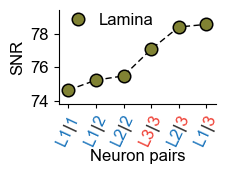

In [9]:
figure_ordered(['Lamina'], *box('B'), save='Fig3B_SNR_LaminaPairs.pdf')

## Fig. 3C

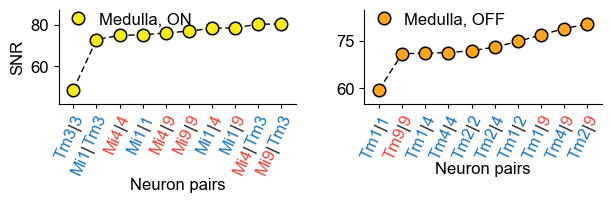

In [10]:
figure_ordered(['ON Medulla', 'OFF Medulla'], *box('C'), save='Fig3C_SNR_MedullaPairs.pdf')

## Fig. 3D

Pairs: r = 0.72
Triplets: r = 0.62


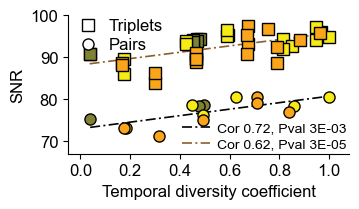

In [11]:
bw, bh = box('D')
Fig = plt.figure(figsize=(M_L + bw + M_R, 0.62 + bh + M_T))
ax  = axes_inches(Fig, M_L, 0.62, bw, bh)

fit_handles, spans = [], []
for m in SIZES:
    keys = NONRED_ALL[m]
    d = np.array([D_F[m][key] for key in keys])
    y = np.array([snr_at(m, K_NAT, key) for key in keys])
    spans.append(y)
    for pathway in CIRCUITS:
        sel = np.array([c == pathway for c, _ in keys])
        ax.plot(d[sel], y[sel], ls='none', marker=MARKER_N[m], markersize=8,
                markerfacecolor=COLOR_PATHWAY[pathway], markeredgecolor='k',
                markeredgewidth=1.0, zorder=3)
    b1, b0 = np.polyfit(d, y, 1)
    xs = np.linspace(d.min(), d.max(), 50)
    ax.plot(xs, b1 * xs + b0, ls=FIT_STYLE, color=FIT_COLOR[m], lw=1.2, zorder=2)
    r, p = pearsonr(d, y)
    print(f'{SIZE_NAME[m]}: r = {r:.2f}')
    fit_handles.append(Line2D([], [], ls=FIT_STYLE, color=FIT_COLOR[m], lw=1.2,
                              label=f'Cor {r:.2f}, Pval {p:.0E}'))

allv = np.concatenate(spans)
lo, hi = allv.min(), allv.max()
ax.set_ylim(lo - 0.16 * (hi - lo), hi + 0.10 * (hi - lo))
ax.set_xlim(-0.05, 1.08)
ax.set_xticks(np.arange(0.0, 1.01, 0.2))
ax.set_xlabel('Temporal diversity coefficient')
ax.set_ylabel('SNR')
ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
strip_spines(ax)

sizes = ax.legend(handles=[Line2D([], [], ls='none', marker=MARKER_N[m], markersize=8,
                                  markerfacecolor='w', markeredgecolor='k',
                                  markeredgewidth=1.0, label=SIZE_NAME[m])
                           for m in SIZES[::-1]],
                  loc='upper left', frameon=False, handletextpad=0.25, labelspacing=0.25,
                  borderpad=0.0, borderaxespad=0.2)
ax.add_artist(sizes)
ax.legend(handles=fit_handles, loc='lower right', frameon=False, fontsize=10,
          handletextpad=0.5, labelspacing=0.25, borderpad=0.0, borderaxespad=0.2)

Fig.savefig(PATH_PDF / 'Fig3D_SNR_vs_TemporalDiversity.pdf', bbox_inches='tight')
plt.show()

## Fig. 3E, F

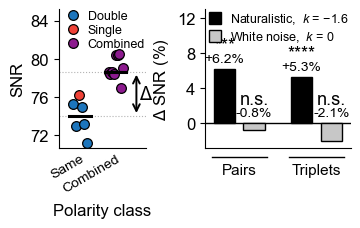

    Pairs  naturalistic   Delta = +6.2%
    Pairs   white noise   Delta = -0.8%
 Triplets  naturalistic   Delta = +5.3%
 Triplets   white noise   Delta = -2.1%
Pairs, naturalistic: permutation p = 0.08 (72 assignments)
Triplets, naturalistic: permutation p = 0.03 (72 assignments)


In [12]:
COLOR_STIM = {K_NAT: 'k', K_WN: '0.78'}
BAR_LABEL  = {K_NAT: 'Naturalistic,  ' + r'$k$ = −1.6', K_WN: 'White noise,  ' + r'$k$ = 0'}
STIM_NAME  = {K_NAT: 'naturalistic', K_WN: 'white noise'}
CLASS_NAME = {'S': 'Single', 'D': 'Double', 'C': 'Combined'}


def stars(p):
    return ('****' if p < 1e-4 else '***' if p < 1e-3 else
            '**' if p < 1e-2 else '*' if p < 0.05 else 'n.s.')


def polarity_delta(snr, keys, polarity=polarity_of):
    # Eq. 25, in %
    same = [v for v, key in zip(snr, keys) if pol_class(key[1], polarity) != 'C']
    comb = [v for v, key in zip(snr, keys) if pol_class(key[1], polarity) == 'C']
    return 100.0 * (np.median(comb) / np.median(same) - 1.0)


def polarity_effect(m, k):
    keys = NONRED_ALL[m]
    same = [key for key in keys if pol_class(key[1]) != 'C']
    comb = [key for key in keys if pol_class(key[1]) == 'C']
    g_same = np.array([snr_at_matched(m, k, key) for key in same])
    g_comb = np.array([snr_at_matched(m, k, key) for key in comb])
    return dict(delta=100.0 * (np.median(g_comb) / np.median(g_same) - 1.0),
                p=float(mannwhitneyu(g_comb, g_same, alternative='greater').pvalue),
                same=g_same, comb=g_comb, keys_same=same, keys_comb=comb)


def permutation_p(m, k):
    # one-sided p over all reassignments of the polarity classes to the cell types within each
    # pathway, number of single-polarity types per pathway fixed (3 x 6 x 4 = 72)
    keys = NONRED_ALL[m]
    snr  = [snr_at_matched(m, k, key) for key in keys]
    per_pathway = [list(combinations(cts, sum(polarity_of[ct] == 'single' for ct in cts)))
                   for cts in CIRCUITS.values()]
    deltas = []
    for singles in product(*per_pathway):
        single = {ct for group in singles for ct in group}
        deltas.append(polarity_delta(snr, keys, {ct: ('single' if ct in single else 'double')
                                                 for ct in CELL_TYPES}))
    deltas = np.array(deltas)
    return np.mean(deltas >= polarity_delta(snr, keys) - 1e-9), len(deltas)


bars = [(m, k) for m in SIZES for k in (K_NAT, K_WN)]
res  = [polarity_effect(m, k) for m, k in bars]

wA, sep, wB = (w * SCALE for w in (0.538, 0.365, 0.896))
bh  = box('D')[1]
Fig = plt.figure(figsize=(M_L + wA + sep + wB + M_R, 0.78 + bh + M_T))
axA = axes_inches(Fig, M_L, 0.78, wA, bh)
axB = axes_inches(Fig, M_L + wA + sep, 0.78, wB, bh)

# E: naturalistic pairs, same vs combined polarity
r0 = res[0]
for gi, (vals, keys) in enumerate(((r0['same'], r0['keys_same']), (r0['comb'], r0['keys_comb']))):
    xj = gi + np.linspace(-0.20, 0.20, vals.size)
    for x0, y0, k0 in zip(xj, vals, keys):
        axA.plot(x0, y0, MARKER_N[2], markersize=7,
                 markerfacecolor=COLOR_CLASS[pol_class(k0[1])], markeredgecolor='k',
                 markeredgewidth=0.9, zorder=3)
    axA.axhline(np.median(vals), color='0.7', lw=0.8, ls=':', zorder=1)
    axA.plot([gi - 0.30, gi + 0.30], [np.median(vals)] * 2, '-', color='k', lw=2.2, zorder=4)

axA.annotate('', xy=(1.58, np.median(r0['comb'])), xytext=(1.58, np.median(r0['same'])),
             arrowprops=dict(arrowstyle='<->', color='k', lw=1.4))
axA.text(1.66, 0.5 * (np.median(r0['same']) + np.median(r0['comb'])), r'$\Delta$',
         fontsize=13, va='center', ha='left')
axA.set_xlim(-0.60, 1.85)
axA.set_xticks([0, 1])
axA.set_xticklabels(['Same', 'Combined'], fontsize=10, rotation=30, ha='right',
                    rotation_mode='anchor')
axA.set_xlabel('Polarity class', labelpad=6)
axA.set_ylabel('SNR')
axA.yaxis.set_major_locator(MaxNLocator(nbins=4))
y0, y1 = axA.get_ylim()
axA.set_ylim(y0, y0 + (y1 - y0) * 1.42)
axA.tick_params(axis='x', length=0)
strip_spines(axA)
axA.legend(handles=[Line2D([], [], ls='none', marker='o', markersize=7,
                           markerfacecolor=COLOR_CLASS[c], markeredgecolor='k',
                           markeredgewidth=0.9, label=CLASS_NAME[c]) for c in 'DSC'],
           loc='upper left', frameon=False, fontsize=9, handletextpad=0.2,
           labelspacing=0.15, borderpad=0.0, borderaxespad=0.1)

# F: Delta for pairs and triplets, naturalistic and white noise at matched power
xb   = np.array([0.0, 1.0, 2.6, 3.6])
_d   = [r['delta'] for r in res]
hi   = 2.10 * max(_d)
lo   = min(0.0, 1.35 * min(_d))
span = hi - lo
if lo < 0:
    axB.axhline(0, color='k', lw=1.0, zorder=2)
for x, (m, k), r in zip(xb, bars, res):
    axB.bar(x, r['delta'], width=0.72, color=COLOR_STIM[k], edgecolor='k', lw=1.0, zorder=3)
    _y = max(r['delta'], 0.0)
    axB.text(x, _y + 0.025 * span, f"{r['delta']:+.1f}%", ha='center', va='bottom',
             fontsize=10, zorder=4)
    axB.text(x, _y + 0.105 * span, stars(r['p']), ha='center', va='bottom',
             fontsize=13, zorder=4)
axB.set_xticks(xb)
axB.set_xticklabels([''] * len(xb))
axB.set_xlim(-0.65, 4.25)
axB.set_ylim(lo, hi)
axB.set_ylabel(r'$\Delta$ SNR (%)')
axB.yaxis.set_major_locator(MaxNLocator(nbins=4))
axB.tick_params(axis='x', length=0)
strip_spines(axB)
axB.legend(handles=[Line2D([], [], ls='none', marker='s', markersize=9,
                           markerfacecolor=COLOR_STIM[k], markeredgecolor='k',
                           markeredgewidth=1.0, label=BAR_LABEL[k]) for k in (K_NAT, K_WN)],
           loc='upper right', frameon=False, fontsize=9, handletextpad=0.25,
           labelspacing=0.2, borderpad=0.0, borderaxespad=0.1)

tr = axB.get_xaxis_transform()
for m, xs in ((2, xb[:2]), (3, xb[2:])):
    axB.plot([xs[0] - 0.42, xs[1] + 0.42], [-0.07] * 2, transform=tr, color='k', lw=1.0,
             clip_on=False)
    axB.text(xs.mean(), -0.11, SIZE_NAME[m], transform=tr, ha='center', va='top', fontsize=11)

Fig.savefig(PATH_PDF / 'Fig3EF_PolarityEffect_NaturalVsWhite.pdf', bbox_inches='tight')
plt.show()

for (m, k), r in zip(bars, res):
    print(f"{SIZE_NAME[m]:>9s}  {STIM_NAME[k]:>12s}   Delta = {r['delta']:+.1f}%")
for m in SIZES:
    p, n = permutation_p(m, K_NAT)
    print(f'{SIZE_NAME[m]}, naturalistic: permutation p = {p:.2f} ({n} assignments)')